# MLB Baseball Operations: Next-Game Total Bases Prediction

## Objective

Build a **hitter forecasting model** that estimates:

> **Given everything known about a hitter through game `t`, how many total bases will he record in game `t+1`?**

This is designed as a baseball-operations / player-evaluation forecasting problem rather than a same-game descriptive Statcast exercise.

### Primary target

\[
\text{Next-Game Total Bases}
= 1(\text{1B}) + 2(\text{2B}) + 3(\text{3B}) + 4(\text{HR})
\]

### Modeling design

- Raw source: pitch-level MLB Statcast / bat-tracking data
- Observation unit after aggregation: **one batter-game**
- Information set: only data available **through the hitter's previous game**
- Training period: **2024 through June 30, 2025 outcomes**
- Validation period: **July 2025 outcomes**
- Untouched test period: **August–September 2025 outcomes**
- Models:
  - historical-mean baseline
  - Ridge regression
  - random forest
  - XGBoost
  - Bayesian hyperparameter optimization with Optuna
- Evaluation:
  - MAE
  - RMSE
  - R²
  - calibration by predicted-total-bases bucket
  - player-level error analysis
- Deployment output: next-game total-bases projection for each hitter based on his latest available game

The notebook reads the large pitch file in **chunks**, so the full Kaggle CSV does not need to fit into memory at once.


In [1]:
# Core imports
from pathlib import Path
import os
import warnings
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_TRIALS = int(os.getenv("OPTUNA_TRIALS", "20"))
CHUNK_SIZE = int(os.getenv("STATCAST_CHUNK_SIZE", "250000"))

pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 180)


## 1. Locate the full Statcast CSV

The uploaded sample establishes the schema, including `game_date`, `batter`, `events`, batted-ball quality fields, and bat-tracking fields.

The full Kaggle file is intentionally not hard-coded to one exact filename. The loader:

1. checks common names,
2. scans local CSV files,
3. selects the first file containing the required Statcast columns.

This makes the notebook portable while avoiding accidental use of an unrelated CSV.


In [2]:
COMMON_NAMES = [
    Path("statcast_2024_2025.csv"),
    Path("mlb_statcast_2024_2025.csv"),
    Path("statcast_bat_tracking_2024_2025.csv"),
    Path("mlb_statcast_bat_tracking_2024_2025.csv"),
    Path("statcast.csv"),
]

REQUIRED_COLUMNS = {"game_date", "game_pk", "batter", "events", "description"}
OPTIONAL_COLUMNS = {
    "launch_speed", "launch_angle", "launch_speed_angle",
    "estimated_woba_using_speedangle", "bat_speed", "swing_length",
    "age_bat", "home_team", "away_team", "game_type"
}

search_paths = []
for p in COMMON_NAMES:
    search_paths.extend([p, Path("/mnt/data") / p.name])

search_paths.extend(sorted(Path(".").glob("*.csv")))
if Path("/mnt/data").exists():
    search_paths.extend(sorted(Path("/mnt/data").glob("*.csv")))

seen = set()
DATA_PATH = None
available_columns = None

for path in search_paths:
    path = Path(path)
    if path in seen or not path.exists():
        continue
    seen.add(path)
    try:
        cols = set(pd.read_csv(path, nrows=0).columns)
    except Exception:
        continue
    if REQUIRED_COLUMNS.issubset(cols):
        DATA_PATH = path
        available_columns = cols
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find the full Statcast CSV. Put it beside this notebook or in /mnt/data. "
        f"It must contain at least: {sorted(REQUIRED_COLUMNS)}"
    )

USECOLS = sorted(REQUIRED_COLUMNS | (OPTIONAL_COLUMNS & available_columns))

print("Statcast file:", DATA_PATH)
print("Columns read:", len(USECOLS))
print(USECOLS)


Statcast file: statcast_bat_tracking_2024_2025.csv
Columns read: 15
['age_bat', 'away_team', 'bat_speed', 'batter', 'description', 'estimated_woba_using_speedangle', 'events', 'game_date', 'game_pk', 'game_type', 'home_team', 'launch_angle', 'launch_speed', 'launch_speed_angle', 'swing_length']


## 2. Aggregate the large pitch file to batter-game rows

The raw file is pitch-level, but the prediction target is next-game hitter production.

For each batter-game we construct:

- plate appearances,
- total bases,
- hits / doubles / triples / home runs,
- walks and strikeouts,
- pitches seen,
- swings and whiffs,
- batted-ball count,
- average / maximum exit velocity,
- hard-hit count,
- barrel count,
- average launch angle,
- expected wOBA on contact,
- average bat speed,
- average swing length.

All aggregation quantities are represented as sums/counts so separate CSV chunks can be recombined exactly.


In [3]:
HIT_TB = {
    "single": 1,
    "double": 2,
    "triple": 3,
    "home_run": 4,
}

HIT_EVENTS = set(HIT_TB)
WALK_EVENTS = {"walk", "intent_walk"}
STRIKEOUT_EVENTS = {"strikeout", "strikeout_double_play"}

SWING_DESCRIPTIONS = {
    "swinging_strike", "swinging_strike_blocked",
    "foul", "foul_tip", "hit_into_play",
    "foul_bunt", "missed_bunt"
}
WHIFF_DESCRIPTIONS = {
    "swinging_strike", "swinging_strike_blocked", "missed_bunt"
}

def _num(series):
    return pd.to_numeric(series, errors="coerce")

def aggregate_statcast_chunk(chunk):
    x = chunk.copy()
    x["game_date"] = pd.to_datetime(x["game_date"], errors="coerce")
    x = x[x["game_date"].notna() & x["batter"].notna() & x["game_pk"].notna()].copy()

    if "game_type" in x.columns:
        x = x[x["game_type"].astype(str).eq("R")].copy()

    events = x["events"].fillna("").astype(str)
    desc = x["description"].fillna("").astype(str)

    x["_pa"] = events.ne("").astype(int)
    x["_tb"] = events.map(HIT_TB).fillna(0).astype(float)
    x["_hit"] = events.isin(HIT_EVENTS).astype(int)
    x["_double"] = events.eq("double").astype(int)
    x["_triple"] = events.eq("triple").astype(int)
    x["_hr"] = events.eq("home_run").astype(int)
    x["_walk"] = events.isin(WALK_EVENTS).astype(int)
    x["_strikeout"] = events.isin(STRIKEOUT_EVENTS).astype(int)
    x["_hbp"] = events.eq("hit_by_pitch").astype(int)
    x["_swing"] = desc.isin(SWING_DESCRIPTIONS).astype(int)
    x["_whiff"] = desc.isin(WHIFF_DESCRIPTIONS).astype(int)
    x["_pitch"] = 1

    if "launch_speed" in x.columns:
        ev = _num(x["launch_speed"])
        x["_ev_sum"] = ev.fillna(0.0)
        x["_ev_count"] = ev.notna().astype(int)
        x["_ev_max"] = ev
        x["_hard_hit"] = (ev >= 95).astype(int)
    else:
        x["_ev_sum"] = 0.0
        x["_ev_count"] = 0
        x["_ev_max"] = np.nan
        x["_hard_hit"] = 0

    if "launch_angle" in x.columns:
        la = _num(x["launch_angle"])
        x["_la_sum"] = la.fillna(0.0)
        x["_la_count"] = la.notna().astype(int)
    else:
        x["_la_sum"] = 0.0
        x["_la_count"] = 0

    if "launch_speed_angle" in x.columns:
        x["_barrel"] = (_num(x["launch_speed_angle"]) == 6).astype(int)
    else:
        x["_barrel"] = 0

    if "estimated_woba_using_speedangle" in x.columns:
        xwoba = _num(x["estimated_woba_using_speedangle"])
        x["_xwoba_sum"] = xwoba.fillna(0.0)
        x["_xwoba_count"] = xwoba.notna().astype(int)
    else:
        x["_xwoba_sum"] = 0.0
        x["_xwoba_count"] = 0

    if "bat_speed" in x.columns:
        bs = _num(x["bat_speed"])
        x["_bat_speed_sum"] = bs.fillna(0.0)
        x["_bat_speed_count"] = bs.notna().astype(int)
    else:
        x["_bat_speed_sum"] = 0.0
        x["_bat_speed_count"] = 0

    if "swing_length" in x.columns:
        sl = _num(x["swing_length"])
        x["_swing_length_sum"] = sl.fillna(0.0)
        x["_swing_length_count"] = sl.notna().astype(int)
    else:
        x["_swing_length_sum"] = 0.0
        x["_swing_length_count"] = 0

    if "age_bat" in x.columns:
        x["_age_sum"] = _num(x["age_bat"]).fillna(0.0)
        x["_age_count"] = _num(x["age_bat"]).notna().astype(int)
    else:
        x["_age_sum"] = 0.0
        x["_age_count"] = 0

    group_cols = ["batter", "game_pk", "game_date"]
    summed = [
        "_pa", "_tb", "_hit", "_double", "_triple", "_hr", "_walk",
        "_strikeout", "_hbp", "_swing", "_whiff", "_pitch",
        "_ev_sum", "_ev_count", "_hard_hit", "_barrel",
        "_la_sum", "_la_count", "_xwoba_sum", "_xwoba_count",
        "_bat_speed_sum", "_bat_speed_count",
        "_swing_length_sum", "_swing_length_count",
        "_age_sum", "_age_count"
    ]

    out = x.groupby(group_cols, as_index=False)[summed].sum()

    ev_max = (
        x.groupby(group_cols, as_index=False)["_ev_max"]
        .max()
    )
    out = out.merge(ev_max, on=group_cols, how="left")
    return out


In [4]:
chunk_summaries = []

reader = pd.read_csv(
    DATA_PATH,
    usecols=USECOLS,
    chunksize=CHUNK_SIZE,
    low_memory=False,
)

for i, chunk in enumerate(reader, start=1):
    chunk_summaries.append(aggregate_statcast_chunk(chunk))
    if i == 1 or i % 5 == 0:
        print(f"Processed {i:,} chunks")

games_raw = pd.concat(chunk_summaries, ignore_index=True)

print("Intermediate batter-game fragments:", games_raw.shape)


Processed 1 chunks
Processed 5 chunks
Intermediate batter-game fragments: (97631, 30)


## 3. Recombine games that crossed chunk boundaries

A batter-game can be split between two CSV chunks. We therefore group the intermediate summaries a second time.

For additive statistics we sum across fragments. For maximum exit velocity we take the maximum.


In [5]:
GROUP_COLS = ["batter", "game_pk", "game_date"]

sum_cols = [
    c for c in games_raw.columns
    if c.startswith("_") and c != "_ev_max"
]

games = (
    games_raw.groupby(GROUP_COLS, as_index=False)[sum_cols]
    .sum()
)

ev_max = (
    games_raw.groupby(GROUP_COLS, as_index=False)["_ev_max"]
    .max()
)

games = games.merge(ev_max, on=GROUP_COLS, how="left")
games = games.sort_values(["batter", "game_date", "game_pk"]).reset_index(drop=True)

print("Unique batter-games:", len(games))
print("Date range:", games["game_date"].min().date(), "to", games["game_date"].max().date())
print("Unique hitters:", games["batter"].nunique())


Unique batter-games: 97579
Date range: 2024-03-20 to 2025-09-28
Unique hitters: 788


## 4. Convert aggregation components into baseball features

The chunk-safe sums/counts are converted into interpretable rates and averages.

Importantly, these are still statistics from the **current completed game**. The target will be the hitter's **following game**, so the current game is part of the valid information set.


In [6]:
def safe_divide(num, den):
    num = pd.to_numeric(num, errors="coerce")
    den = pd.to_numeric(den, errors="coerce")
    return num / den.replace(0, np.nan)

games["plate_appearances"] = games["_pa"]
games["total_bases"] = games["_tb"]
games["hits"] = games["_hit"]
games["doubles"] = games["_double"]
games["triples"] = games["_triple"]
games["home_runs"] = games["_hr"]
games["walks"] = games["_walk"]
games["strikeouts"] = games["_strikeout"]
games["hbp"] = games["_hbp"]
games["pitches_seen"] = games["_pitch"]

games["swing_rate"] = safe_divide(games["_swing"], games["_pitch"])
games["whiff_rate"] = safe_divide(games["_whiff"], games["_swing"])
games["hard_hit_rate"] = safe_divide(games["_hard_hit"], games["_ev_count"])
games["barrel_rate"] = safe_divide(games["_barrel"], games["_ev_count"])

games["avg_exit_velocity"] = safe_divide(games["_ev_sum"], games["_ev_count"])
games["max_exit_velocity"] = games["_ev_max"]
games["avg_launch_angle"] = safe_divide(games["_la_sum"], games["_la_count"])
games["avg_xwoba_contact"] = safe_divide(games["_xwoba_sum"], games["_xwoba_count"])
games["avg_bat_speed"] = safe_divide(games["_bat_speed_sum"], games["_bat_speed_count"])
games["avg_swing_length"] = safe_divide(games["_swing_length_sum"], games["_swing_length_count"])
games["age"] = safe_divide(games["_age_sum"], games["_age_count"])

games["hit_rate_pa"] = safe_divide(games["hits"], games["plate_appearances"])
games["hr_rate_pa"] = safe_divide(games["home_runs"], games["plate_appearances"])
games["bb_rate_pa"] = safe_divide(games["walks"], games["plate_appearances"])
games["k_rate_pa"] = safe_divide(games["strikeouts"], games["plate_appearances"])

display(games[
    ["batter", "game_date", "plate_appearances", "total_bases",
     "avg_exit_velocity", "hard_hit_rate", "barrel_rate",
     "avg_bat_speed", "avg_swing_length"]
].head(10))


,batter,game_date,plate_appearances,total_bases,avg_exit_velocity,hard_hit_rate,barrel_rate,avg_bat_speed,avg_swing_length
0,444482,2024-05-22,2,0.0,66.900000,0.000000,0.0,69.100000,7.066667
1,444482,2024-05-23,5,3.0,79.633333,0.166667,0.0,70.090909,6.863636
2,444482,2024-05-24,1,0.0,NaN,NaN,NaN,70.300000,7.100000
3,444482,2024-05-25,4,0.0,76.414286,0.142857,0.0,66.554545,7.100000
4,444482,2024-05-26,2,0.0,75.100000,0.000000,0.0,66.740000,7.020000
5,444482,2024-05-27,1,0.0,55.100000,0.000000,0.0,74.000000,7.000000
6,444482,2024-05-31,2,0.0,97.600000,1.000000,0.0,68.075000,6.725000
7,444482,2024-06-03,1,0.0,90.400000,0.666667,0.0,72.433333,7.066667
8,444482,2024-06-04,1,0.0,93.800000,0.000000,0.0,79.000000,7.400000
9,444482,2024-06-05,3,0.0,77.066667,0.000000,0.0,64.100000,7.166667


## 5. Construct the next-game target

For each hitter we order games chronologically and shift the game outcome forward one row.

A row therefore means:

> **features through game `t` → total bases in the same batter's game `t+1`**

The final game for each hitter is unlabeled and becomes the deployment-style forecast population.


In [7]:
games["target_game_date"] = games.groupby("batter")["game_date"].shift(-1)
games["target_total_bases"] = games.groupby("batter")["total_bases"].shift(-1)
games["target_plate_appearances"] = games.groupby("batter")["plate_appearances"].shift(-1)

games["days_since_prev_game"] = (
    games["game_date"]
    - games.groupby("batter")["game_date"].shift(1)
).dt.days

games["days_to_target_game"] = (
    games["target_game_date"] - games["game_date"]
).dt.days

print("Labeled transitions:", games["target_total_bases"].notna().sum())
print("Unlabeled latest hitter rows:", games["target_total_bases"].isna().sum())


Labeled transitions: 96791
Unlabeled latest hitter rows: 788


## 6. Target distribution

Total bases is a noisy, zero-heavy game-level outcome. That makes a mean prediction difficult to beat by large margins.

The model is therefore judged mainly on **MAE and RMSE**, while R² is reported as an additional diagnostic rather than the sole definition of success.


,batter-games
target_total_bases,
0.0,41192
1.0,23873
2.0,13450
3.0,5369
4.0,6799
5.0,3128
6.0,1559
7.0,547
8.0,508


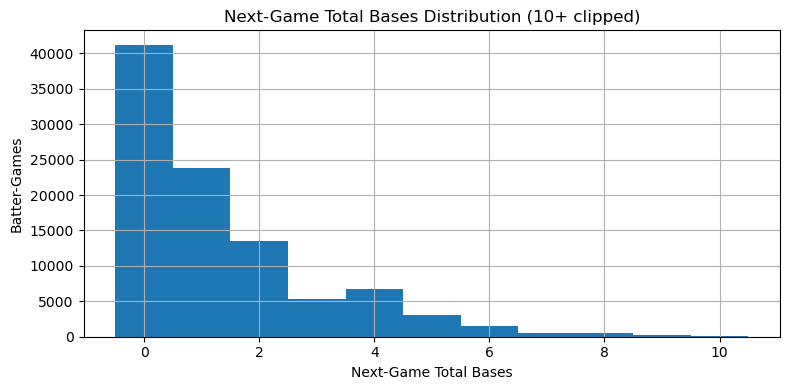

Mean: 1.349
Median: 1.0
Zero rate: 0.426


In [8]:
labeled = games[games["target_total_bases"].notna()].copy()

display(
    labeled["target_total_bases"]
    .value_counts()
    .sort_index()
    .head(12)
    .to_frame("batter-games")
)

plt.figure(figsize=(8, 4))
labeled["target_total_bases"].clip(upper=10).hist(bins=np.arange(-0.5, 11.5, 1))
plt.title("Next-Game Total Bases Distribution (10+ clipped)")
plt.xlabel("Next-Game Total Bases")
plt.ylabel("Batter-Games")
plt.tight_layout()
plt.show()

print("Mean:", round(labeled["target_total_bases"].mean(), 3))
print("Median:", round(labeled["target_total_bases"].median(), 3))
print("Zero rate:", round((labeled["target_total_bases"] == 0).mean(), 3))


## 7. Leakage-aware rolling form features

For every batter-game, rolling statistics use games **through the current game only**. Since the target is the following game, this is valid historical information.

We create:

- 5 / 10 / 20-game rolling form,
- expanding season-to-date / history-to-date performance,
- exponentially weighted recent form,
- workload and contact-quality trends,
- prior-game rest.

No statistics from the target game are used as features.


In [9]:
BASE_ROLLING = [
    "total_bases", "plate_appearances", "hits", "home_runs",
    "walks", "strikeouts", "pitches_seen",
    "avg_exit_velocity", "max_exit_velocity",
    "hard_hit_rate", "barrel_rate", "avg_launch_angle",
    "avg_xwoba_contact", "avg_bat_speed", "avg_swing_length",
    "swing_rate", "whiff_rate", "hit_rate_pa",
    "hr_rate_pa", "bb_rate_pa", "k_rate_pa"
]

def add_rolling_features(df):
    out = df.sort_values(["batter", "game_date", "game_pk"]).copy()
    g = out.groupby("batter", group_keys=False)

    out["games_played_to_date"] = g.cumcount() + 1

    for col in BASE_ROLLING:
        if col not in out.columns:
            continue
        for window in (5, 10, 20):
            out[f"{col}_roll{window}"] = (
                g[col]
                .rolling(window, min_periods=1)
                .mean()
                .reset_index(level=0, drop=True)
            )

    out["tb_expanding_mean"] = (
        g["total_bases"]
        .expanding(min_periods=1)
        .mean()
        .reset_index(level=0, drop=True)
    )

    out["pa_expanding_mean"] = (
        g["plate_appearances"]
        .expanding(min_periods=1)
        .mean()
        .reset_index(level=0, drop=True)
    )

    out["tb_ewm5"] = g["total_bases"].transform(
        lambda s: s.ewm(span=5, adjust=False).mean()
    )
    out["tb_ewm10"] = g["total_bases"].transform(
        lambda s: s.ewm(span=10, adjust=False).mean()
    )
    out["ev_ewm10"] = g["avg_exit_velocity"].transform(
        lambda s: s.ewm(span=10, adjust=False, ignore_na=True).mean()
    )
    out["hard_hit_ewm10"] = g["hard_hit_rate"].transform(
        lambda s: s.ewm(span=10, adjust=False, ignore_na=True).mean()
    )

    return out

model_df = add_rolling_features(games)

print("Model rows:", model_df.shape)
print("Total columns after feature engineering:", model_df.shape[1])


Model rows: (97579, 130)
Total columns after feature engineering: 130


## 8. Strict chronological split

We split by the **date of the outcome being predicted**, not the feature-game date.

| Set | Target-game date | Purpose |
|---|---|---|
| Train | through June 30, 2025 | model fitting |
| Validation | July 1–31, 2025 | model / hyperparameter selection |
| Test | August 1, 2025 onward | untouched final evaluation |
| Forecast | each hitter's latest row | next game unknown |

All 2024 outcomes are part of training.

If a different version of the Kaggle file ends earlier than August 2025, the notebook automatically falls back to chronological 70/15/15 date cutoffs.


In [10]:
labeled_df = model_df[model_df["target_total_bases"].notna()].copy()
labeled_df = labeled_df[labeled_df["target_game_date"].notna()].copy()

target_dates = np.array(sorted(labeled_df["target_game_date"].dt.normalize().unique()))
max_target_date = pd.Timestamp(labeled_df["target_game_date"].max())

if max_target_date >= pd.Timestamp("2025-08-01"):
    train_df = labeled_df[labeled_df["target_game_date"] <= "2025-06-30"].copy()
    val_df = labeled_df[
        labeled_df["target_game_date"].between("2025-07-01", "2025-07-31")
    ].copy()
    test_df = labeled_df[labeled_df["target_game_date"] >= "2025-08-01"].copy()
    split_description = "Fixed 2025 baseball-season split"
else:
    if len(target_dates) < 6:
        raise ValueError(
            "The sample is too short for chronological modeling. "
            "Run this notebook with the full Statcast CSV."
        )
    cut1 = pd.Timestamp(target_dates[int(len(target_dates) * 0.70)])
    cut2 = pd.Timestamp(target_dates[int(len(target_dates) * 0.85)])
    train_df = labeled_df[labeled_df["target_game_date"] <= cut1].copy()
    val_df = labeled_df[
        (labeled_df["target_game_date"] > cut1)
        & (labeled_df["target_game_date"] <= cut2)
    ].copy()
    test_df = labeled_df[labeled_df["target_game_date"] > cut2].copy()
    split_description = f"Fallback chronological split: {cut1.date()} / {cut2.date()}"

forecast_df = (
    model_df.sort_values(["batter", "game_date", "game_pk"])
    .groupby("batter", as_index=False)
    .tail(1)
    .copy()
)

print(split_description)
print("Train:", train_df.shape, train_df["target_game_date"].min().date(), "to", train_df["target_game_date"].max().date())
print("Validation:", val_df.shape, val_df["target_game_date"].min().date(), "to", val_df["target_game_date"].max().date())
print("Test:", test_df.shape, test_df["target_game_date"].min().date(), "to", test_df["target_game_date"].max().date())
print("Forecast hitters:", len(forecast_df))


Fixed 2025 baseball-season split
Train: (73285, 130) 2024-03-21 to 2025-06-30
Validation: (7383, 130) 2025-07-01 to 2025-07-31
Test: (16123, 130) 2025-08-01 to 2025-09-28
Forecast hitters: 788


## 9. Final feature set

Identifiers, dates, raw aggregation helpers, and future-target fields are excluded.

The model uses transparent hitter form / contact-quality variables only. Batter ID is deliberately excluded to test whether the model learns generalizable performance patterns rather than memorizing individual players.


In [11]:
EXACT_EXCLUDE = {
    "batter", "game_pk", "game_date", "target_game_date",
    "target_total_bases", "target_plate_appearances",
    "days_to_target_game",
}

def should_exclude(col):
    if col in EXACT_EXCLUDE:
        return True
    if col.startswith("_"):
        return True
    return False

candidate_features = [
    c for c in model_df.columns
    if not should_exclude(c)
    and pd.api.types.is_numeric_dtype(model_df[c])
]

missing_rate = train_df[candidate_features].isna().mean()
nunique = train_df[candidate_features].nunique(dropna=True)

features = [
    c for c in candidate_features
    if missing_rate[c] <= 0.90 and nunique[c] > 1
]

print("Candidate numeric features:", len(candidate_features))
print("Final features:", len(features))
display(pd.DataFrame({
    "feature": features,
    "missing_rate_train": [missing_rate[c] for c in features],
}).head(30))


Candidate numeric features: 96
Final features: 96


,feature,missing_rate_train
0,plate_appearances,0.000000
1,total_bases,0.000000
2,hits,0.000000
3,doubles,0.000000
4,triples,0.000000
5,home_runs,0.000000
6,walks,0.000000
7,strikeouts,0.000000
8,hbp,0.000000
9,pitches_seen,0.000000


In [12]:
X_train = train_df[features]
y_train = train_df["target_total_bases"].astype(float)

X_val = val_df[features]
y_val = val_df["target_total_bases"].astype(float)

X_test = test_df[features]
y_test = test_df["target_total_bases"].astype(float)

X_forecast = forecast_df[features]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


X_train: (73285, 96)
X_val: (7383, 96)
X_test: (16123, 96)


## 10. Preprocessing

All model features are numeric.

The pipeline:

1. median-imputes missing values,
2. standardizes values for the linear benchmark,
3. keeps the transformation fitted on training data only.


In [13]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

tree_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])


## 11. Evaluation helpers

MAE is the primary metric because it is directly interpretable in **total bases per hitter-game**.

RMSE penalizes large misses more heavily. R² is included to show how much game-to-game variance the model explains.


In [14]:
def regression_metrics(y_true, pred):
    pred = np.asarray(pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": mean_squared_error(y_true, pred) ** 0.5,
        "R2": r2_score(y_true, pred),
    }

def print_metrics(name, y_true, pred):
    m = regression_metrics(y_true, pred)
    print(name)
    for k, v in m.items():
        print(f"  {k}: {v:.4f}")
    return m


## 12. Baseline: training-period mean total bases

A useful model must beat the simplest possible forecast: assign every hitter the same historical mean next-game total bases.


In [15]:
baseline_value = float(y_train.mean())
baseline_val_pred = np.full(len(y_val), baseline_value)

baseline_metrics = print_metrics(
    "Historical mean baseline",
    y_val,
    baseline_val_pred
)


Historical mean baseline
  MAE: 1.3364
  RMSE: 1.7668
  R2: -0.0008


## 13. Ridge regression benchmark

Ridge regression provides a strong linear baseline with regularization across the many correlated rolling features.


In [16]:
ridge = Pipeline([
    ("prep", clone(numeric_preprocessor)),
    ("model", Ridge(alpha=10.0)),
])

ridge.fit(X_train, y_train)
ridge_val_pred = np.clip(ridge.predict(X_val), 0, None)

ridge_metrics = print_metrics(
    "Ridge regression",
    y_val,
    ridge_val_pred
)


Ridge regression
  MAE: 1.3260
  RMSE: 1.7397
  R2: 0.0296


## 14. Random forest benchmark

The random forest can capture nonlinear interactions such as the combination of recent contact quality, playing-time volume, and swing decisions.


In [17]:
rf = Pipeline([
    ("prep", clone(tree_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_depth=12,
        min_samples_leaf=8,
        max_features=0.65,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

rf.fit(X_train, y_train)
rf_val_pred = np.clip(rf.predict(X_val), 0, None)

rf_metrics = print_metrics(
    "Random forest",
    y_val,
    rf_val_pred
)


Random forest
  MAE: 1.3289
  RMSE: 1.7413
  R2: 0.0278


## 15. Untuned XGBoost

Gradient boosting is well suited to nonlinear tabular baseball data and provides a strong benchmark before tuning.


In [18]:
xgb_base = Pipeline([
    ("prep", clone(tree_preprocessor)),
    ("model", XGBRegressor(
        n_estimators=700,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=8,
        subsample=0.85,
        colsample_bytree=0.75,
        reg_alpha=0.05,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

xgb_base.fit(X_train, y_train)
xgb_val_pred = np.clip(xgb_base.predict(X_val), 0, None)

xgb_base_metrics = print_metrics(
    "Untuned XGBoost",
    y_val,
    xgb_val_pred
)


Untuned XGBoost
  MAE: 1.3386
  RMSE: 1.7505
  R2: 0.0176


## 16. Bayesian hyperparameter optimization with Optuna

We tune XGBoost against **validation MAE**.

The untouched test period remains completely excluded from optimization.


In [19]:
X_train_tree = tree_preprocessor.fit_transform(X_train)
X_val_tree = tree_preprocessor.transform(X_val)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 1200),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.45, 1.00),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "objective": "reg:squarederror",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    model = XGBRegressor(**params)
    model.fit(X_train_tree, y_train)
    pred = np.clip(model.predict(X_val_tree), 0, None)
    return mean_absolute_error(y_val, pred)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=N_TRIALS)

print("Best validation MAE:", round(study.best_value, 5))
print("Best parameters:")
display(pd.Series(study.best_params).to_frame("value"))


Best validation MAE: 1.31799
Best parameters:


,value
n_estimators,493.000000
learning_rate,0.010639
max_depth,2.000000
min_child_weight,4.487445
subsample,0.900312
colsample_bytree,0.757303
reg_alpha,0.022673
reg_lambda,0.198749


In [20]:
best_xgb = XGBRegressor(
    **study.best_params,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

best_xgb.fit(X_train_tree, y_train)
tuned_val_pred = np.clip(best_xgb.predict(X_val_tree), 0, None)

tuned_metrics = print_metrics(
    "Optuna-tuned XGBoost",
    y_val,
    tuned_val_pred
)


Optuna-tuned XGBoost
  MAE: 1.3180
  RMSE: 1.7389
  R2: 0.0306


## 17. Validation model comparison

The final model is selected by lowest validation MAE. This decision occurs **before** the test period is touched.


In [21]:
validation_predictions = {
    "Historical Mean": baseline_val_pred,
    "Ridge": ridge_val_pred,
    "Random Forest": rf_val_pred,
    "XGBoost": xgb_val_pred,
    "Tuned XGBoost": tuned_val_pred,
}

comparison_rows = []
for name, pred in validation_predictions.items():
    row = {"Model": name}
    row.update(regression_metrics(y_val, pred))
    comparison_rows.append(row)

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(comparison)

best_model_name = comparison.iloc[0]["Model"]
print("Selected model:", best_model_name)


,Model,MAE,RMSE,R2
0,Tuned XGBoost,1.317989,1.738866,0.030567
1,Ridge,1.325991,1.739723,0.029611
2,Random Forest,1.328937,1.741316,0.027833
3,Historical Mean,1.336415,1.766762,-0.000786
4,XGBoost,1.338559,1.750457,0.017600


Selected model: Tuned XGBoost


## 18. Select a practical projection cap

Rare games can produce extremely high total-base totals. A model's mean prediction should remain realistic.

We inspect the training distribution and define a conservative cap from the 99.5th percentile of observed next-game total bases. This cap is learned from training data only.


In [22]:
PREDICTION_CAP = float(max(4.0, y_train.quantile(0.995)))

print("Training 99.5th percentile:", round(y_train.quantile(0.995), 2))
print("Projection cap:", PREDICTION_CAP)


Training 99.5th percentile: 8.0
Projection cap: 8.0


# 19. Final untouched test

After choosing the model class and hyperparameters, we refit on **train + validation** and evaluate once on the untouched test period.

This is the headline estimate of out-of-sample performance.


In [23]:
train_val_df = pd.concat([train_df, val_df], ignore_index=True)

X_train_val = train_val_df[features]
y_train_val = train_val_df["target_total_bases"].astype(float)

final_tree_preprocessor = clone(tree_preprocessor)
X_train_val_tree = final_tree_preprocessor.fit_transform(X_train_val)
X_test_tree = final_tree_preprocessor.transform(X_test)

if best_model_name == "Tuned XGBoost":
    final_model = XGBRegressor(
        **study.best_params,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    final_model.fit(X_train_val_tree, y_train_val)
    test_pred = final_model.predict(X_test_tree)

elif best_model_name == "XGBoost":
    final_model = clone(xgb_base.named_steps["model"])
    final_model.fit(X_train_val_tree, y_train_val)
    test_pred = final_model.predict(X_test_tree)

elif best_model_name == "Random Forest":
    final_model = clone(rf.named_steps["model"])
    final_model.fit(X_train_val_tree, y_train_val)
    test_pred = final_model.predict(X_test_tree)

elif best_model_name == "Ridge":
    final_ridge_prep = clone(numeric_preprocessor)
    X_train_val_ridge = final_ridge_prep.fit_transform(X_train_val)
    X_test_ridge = final_ridge_prep.transform(X_test)
    final_model = clone(ridge.named_steps["model"])
    final_model.fit(X_train_val_ridge, y_train_val)
    test_pred = final_model.predict(X_test_ridge)

else:
    final_model = None
    test_pred = np.full(len(y_test), y_train_val.mean())

test_pred = np.clip(test_pred, 0, PREDICTION_CAP)
test_metrics = print_metrics("Untouched test", y_test, test_pred)


Untouched test
  MAE: 1.3125
  RMSE: 1.7256
  R2: 0.0276


## 20. Test residual distribution

Game-level hitting outcomes are high variance. Residual analysis shows whether errors are centered or whether the model systematically over- or under-predicts.


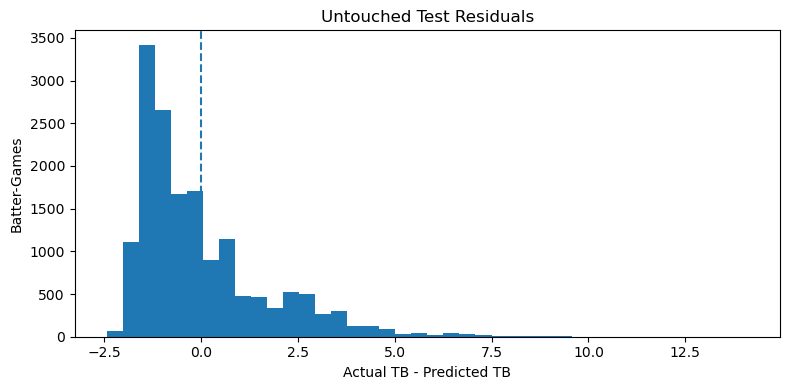

Mean residual: -0.0156
Median absolute error: 1.1469


In [24]:
residuals = y_test.to_numpy() - test_pred

plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=40)
plt.axvline(0, linestyle="--")
plt.title("Untouched Test Residuals")
plt.xlabel("Actual TB - Predicted TB")
plt.ylabel("Batter-Games")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Median absolute error:", round(np.median(np.abs(residuals)), 4))


## 21. Calibration by predicted-total-bases bucket

For a regression forecast, a useful calibration check is:

> When the model predicts higher total bases, do those groups actually produce higher total bases?

Predictions are divided into quantile buckets and compared with realized averages.


,predicted_mean,actual_mean,n
0,0.902075,0.902666,1613
1,1.055045,1.045906,1612
2,1.160511,1.111042,1612
3,1.248974,1.165633,1612
4,1.328037,1.364538,1613
5,1.401133,1.363524,1612
6,1.479679,1.457196,1612
7,1.566721,1.586849,1612
8,1.672731,1.644541,1612
9,1.875578,1.892126,1613


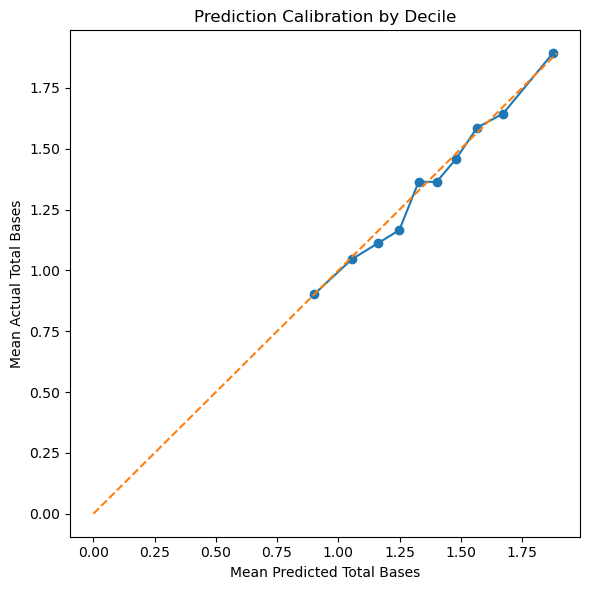

In [25]:
test_output = test_df[
    ["batter", "game_date", "target_game_date", "total_bases",
     "target_total_bases", "games_played_to_date"]
].copy()

test_output["predicted_total_bases"] = test_pred
test_output["absolute_error"] = (
    test_output["target_total_bases"] - test_output["predicted_total_bases"]
).abs()

try:
    test_output["prediction_bucket"] = pd.qcut(
        test_output["predicted_total_bases"],
        q=10,
        duplicates="drop"
    )

    calibration = (
        test_output.groupby("prediction_bucket", observed=True)
        .agg(
            predicted_mean=("predicted_total_bases", "mean"),
            actual_mean=("target_total_bases", "mean"),
            n=("target_total_bases", "size"),
        )
        .reset_index(drop=True)
    )
    display(calibration)

    plt.figure(figsize=(6, 6))
    plt.plot(calibration["predicted_mean"], calibration["actual_mean"], marker="o")
    lim = max(calibration["predicted_mean"].max(), calibration["actual_mean"].max())
    plt.plot([0, lim], [0, lim], linestyle="--")
    plt.xlabel("Mean Predicted Total Bases")
    plt.ylabel("Mean Actual Total Bases")
    plt.title("Prediction Calibration by Decile")
    plt.tight_layout()
    plt.show()
except ValueError:
    print("Not enough unique prediction values for decile calibration.")


## 22. Error by hitter experience

Call-ups and hitters with limited recent history are harder to forecast than established players.

We compare errors based on the number of games available to the model at prediction time.


In [26]:
experience_bins = pd.cut(
    test_output["games_played_to_date"],
    bins=[0, 10, 25, 50, 100, np.inf],
    labels=["1-10", "11-25", "26-50", "51-100", "100+"]
)

experience_error = (
    test_output.assign(experience_group=experience_bins)
    .groupby("experience_group", observed=True)
    .agg(
        n=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        actual_tb=("target_total_bases", "mean"),
        predicted_tb=("predicted_total_bases", "mean"),
    )
)

display(experience_error)


,n,MAE,actual_tb,predicted_tb
experience_group,,,,
1-10,386,1.151937,1.033679,1.127674
11-25,688,1.152566,1.116279,1.075727
26-50,967,1.089024,1.003102,1.136035
51-100,1578,1.189388,1.186312,1.182860
100+,12504,1.359119,1.424504,1.434156


## 23. Strongest and weakest individual test calls

This is useful for baseball-operations review because it surfaces where the model's logic should be examined against actual player context.


In [27]:
display(
    test_output.sort_values("absolute_error")
    .head(15)
)

display(
    test_output.sort_values("absolute_error", ascending=False)
    .head(15)
)


,batter,game_date,target_game_date,total_bases,target_total_bases,games_played_to_date,predicted_total_bases,absolute_error,prediction_bucket
26188,641680,2025-09-24,2025-09-26,1.0,1.0,251,0.999827,0.000173,"(0.993, 1.111]"
39976,663584,2025-08-28,2025-08-30,0.0,1.0,23,0.999671,0.000329,"(0.993, 1.111]"
74561,678554,2025-08-17,2025-08-18,0.0,1.0,97,0.999471,0.000529,"(0.993, 1.111]"
54158,667472,2025-08-19,2025-08-23,0.0,1.0,133,0.999164,0.000836,"(0.993, 1.111]"
60083,669326,2025-09-10,2025-09-11,3.0,1.0,38,0.998930,0.001070,"(0.993, 1.111]"
1425,500743,2025-08-11,2025-08-12,0.0,1.0,169,0.998792,0.001208,"(0.993, 1.111]"
50113,666126,2025-07-30,2025-08-01,1.0,1.0,8,1.001235,0.001235,"(0.993, 1.111]"
81248,682657,2025-08-31,2025-09-02,0.0,1.0,154,0.998657,0.001343,"(0.993, 1.111]"
28920,643289,2025-08-24,2025-08-26,1.0,1.0,224,1.001354,0.001354,"(0.993, 1.111]"
30261,645305,2025-07-30,2025-08-02,1.0,1.0,36,0.998376,0.001624,"(0.993, 1.111]"


,batter,game_date,target_game_date,total_bases,target_total_bases,games_played_to_date,predicted_total_bases,absolute_error,prediction_bucket
35604,656941,2025-08-27,2025-08-28,0.0,16.0,283,1.884592,14.115408,"(1.748, 2.521]"
58309,669127,2025-08-03,2025-08-05,1.0,15.0,217,1.689596,13.310404,"(1.613, 1.748]"
85302,686527,2025-09-14,2025-09-16,4.0,14.0,133,1.165632,12.834368,"(1.111, 1.206]"
46674,665019,2025-09-10,2025-09-12,0.0,14.0,140,1.301747,12.698253,"(1.291, 1.363]"
84395,683737,2025-09-26,2025-09-27,6.0,13.0,299,1.556590,11.443410,"(1.524, 1.613]"
75282,678894,2025-07-30,2025-08-02,1.0,12.0,12,1.051541,10.948459,"(0.993, 1.111]"
23838,624641,2025-09-12,2025-09-24,0.0,12.0,167,1.170737,10.829263,"(1.111, 1.206]"
64991,671277,2025-09-24,2025-09-26,0.0,12.0,275,1.341608,10.658392,"(1.291, 1.363]"
96516,805300,2025-08-12,2025-08-13,0.0,11.0,12,1.297500,9.702500,"(1.291, 1.363]"
19717,621020,2025-08-28,2025-08-29,4.0,11.0,277,1.424273,9.575727,"(1.363, 1.438]"


## 24. Feature importance

For tree models, feature importance identifies the historical signals most useful for forecasting next-game total bases.

For a linear model, standardized absolute coefficients are reported instead.


,feature,importance
32,plate_appearances_roll20,0.130621
31,plate_appearances_roll10,0.099938
90,tb_expanding_mean,0.067105
53,max_exit_velocity_roll20,0.056964
91,pa_expanding_mean,0.053040
29,total_bases_roll20,0.036018
93,tb_ewm10,0.031155
50,avg_exit_velocity_roll20,0.024919
28,total_bases_roll10,0.019649
67,avg_bat_speed_roll10,0.019034


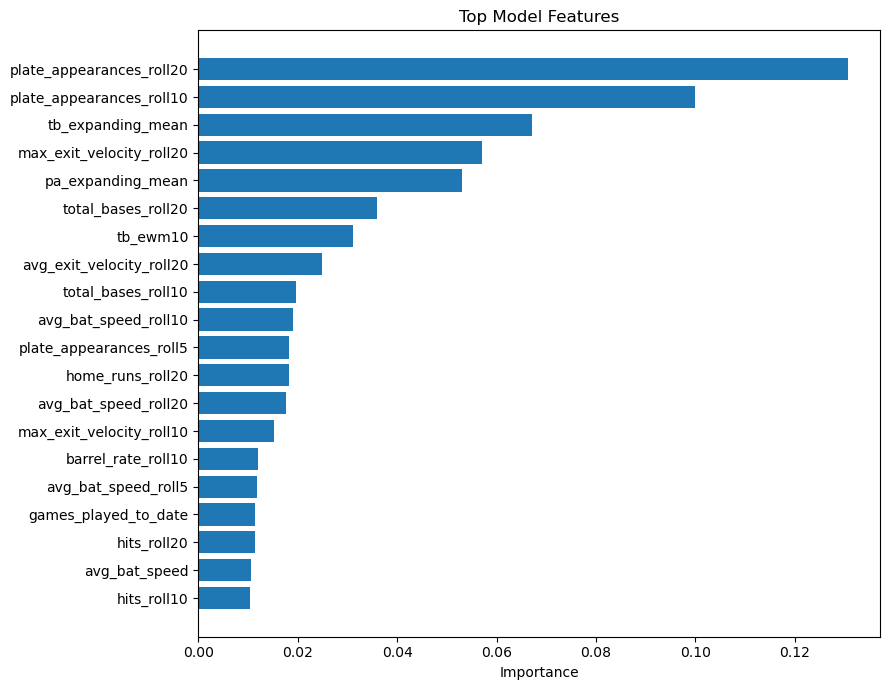

In [28]:
if best_model_name in {"Tuned XGBoost", "XGBoost", "Random Forest"}:
    importance = pd.DataFrame({
        "feature": features,
        "importance": final_model.feature_importances_,
    }).sort_values("importance", ascending=False)

elif best_model_name == "Ridge":
    importance = pd.DataFrame({
        "feature": features,
        "importance": np.abs(final_model.coef_),
    }).sort_values("importance", ascending=False)

else:
    importance = pd.DataFrame(columns=["feature", "importance"])

display(importance.head(25))

if len(importance):
    top_imp = importance.head(20).sort_values("importance")
    plt.figure(figsize=(9, 7))
    plt.barh(top_imp["feature"], top_imp["importance"])
    plt.title("Top Model Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()


# 25. Train deployment model on all labeled games

The final production-style model uses every labeled batter-game.

It then scores each hitter's latest available row to estimate his total bases in the **next game after the dataset ends**.

Because no future schedule / probable starter file is joined, this is a **player-form projection**, not a matchup-specific projection.


In [29]:
all_labeled = model_df[model_df["target_total_bases"].notna()].copy()

X_all = all_labeled[features]
y_all = all_labeled["target_total_bases"].astype(float)
X_latest = forecast_df[features]

if best_model_name in {"Tuned XGBoost", "XGBoost", "Random Forest"}:
    deployment_preprocessor = clone(tree_preprocessor)
    X_all_t = deployment_preprocessor.fit_transform(X_all)
    X_latest_t = deployment_preprocessor.transform(X_latest)

    if best_model_name == "Tuned XGBoost":
        deployment_model = XGBRegressor(
            **study.best_params,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    elif best_model_name == "XGBoost":
        deployment_model = clone(xgb_base.named_steps["model"])
    else:
        deployment_model = clone(rf.named_steps["model"])

    deployment_model.fit(X_all_t, y_all)
    next_game_projection = deployment_model.predict(X_latest_t)

elif best_model_name == "Ridge":
    deployment_preprocessor = clone(numeric_preprocessor)
    X_all_t = deployment_preprocessor.fit_transform(X_all)
    X_latest_t = deployment_preprocessor.transform(X_latest)
    deployment_model = clone(ridge.named_steps["model"])
    deployment_model.fit(X_all_t, y_all)
    next_game_projection = deployment_model.predict(X_latest_t)

else:
    deployment_preprocessor = None
    deployment_model = None
    next_game_projection = np.full(len(forecast_df), y_all.mean())

next_game_projection = np.clip(next_game_projection, 0, PREDICTION_CAP)


## 26. Build the hitter projection board

The board includes:

- batter ID,
- latest game date,
- games of history,
- recent total-bases form,
- recent exit velocity / hard-hit quality,
- projected next-game total bases.


In [30]:
board_cols = [
    "batter", "game_date", "games_played_to_date",
    "total_bases_roll5", "total_bases_roll10", "total_bases_roll20",
    "avg_exit_velocity_roll10", "hard_hit_rate_roll10",
    "barrel_rate_roll10", "avg_bat_speed_roll10"
]

board_cols = [c for c in board_cols if c in forecast_df.columns]

hitter_board = forecast_df[board_cols].copy()
hitter_board["projected_next_game_total_bases"] = next_game_projection

hitter_board = (
    hitter_board.sort_values("projected_next_game_total_bases", ascending=False)
    .reset_index(drop=True)
)

display(hitter_board.head(30))


,batter,game_date,games_played_to_date,total_bases_roll5,total_bases_roll10,total_bases_roll20,avg_exit_velocity_roll10,hard_hit_rate_roll10,barrel_rate_roll10,avg_bat_speed_roll10,projected_next_game_total_bases
0,592450,2025-09-28,310,4.4,2.8,2.85,88.666873,0.444127,0.134444,75.657369,2.549669
1,656941,2025-09-28,312,2.2,1.8,2.05,85.928333,0.335000,0.113333,74.957056,2.046927
2,660271,2025-09-28,315,2.8,3.1,2.90,89.885615,0.386310,0.163730,73.890853,2.045690
3,677594,2025-09-27,301,1.2,1.3,2.10,87.220476,0.359524,0.047619,75.547411,1.955074
4,701762,2025-09-28,117,2.8,2.3,2.15,92.094167,0.401667,0.165000,74.113290,1.932523
5,606466,2025-09-28,262,3.0,2.9,1.75,85.948278,0.366587,0.112063,74.056722,1.927921
6,624413,2025-09-28,322,2.2,2.2,2.15,91.777893,0.402143,0.134286,72.466530,1.919509
7,621566,2025-09-28,322,1.4,1.6,2.55,86.454196,0.277706,0.117821,73.460722,1.914829
8,592518,2025-09-28,311,1.4,1.6,1.80,87.297833,0.298333,0.133889,73.105596,1.896427
9,691406,2025-09-28,197,2.2,1.4,1.90,83.630762,0.260714,0.036905,77.783617,1.880313


## 27. Identify short-term hot-form candidates

A high projection can simply reflect a consistently strong hitter.

To isolate recent form, compare 5-game and 20-game total-bases averages. This is descriptive context around the model, not an additional target.


In [31]:
if {"total_bases_roll5", "total_bases_roll20"}.issubset(hitter_board.columns):
    hitter_board["recent_tb_form_delta"] = (
        hitter_board["total_bases_roll5"] - hitter_board["total_bases_roll20"]
    )

    hot_form = (
        hitter_board[hitter_board["games_played_to_date"] >= 20]
        .sort_values(
            ["projected_next_game_total_bases", "recent_tb_form_delta"],
            ascending=False
        )
        .head(25)
    )
    display(hot_form)
else:
    print("Rolling total-base features unavailable.")


,batter,game_date,games_played_to_date,total_bases_roll5,total_bases_roll10,total_bases_roll20,avg_exit_velocity_roll10,hard_hit_rate_roll10,barrel_rate_roll10,avg_bat_speed_roll10,projected_next_game_total_bases,recent_tb_form_delta
0,592450,2025-09-28,310,4.4,2.8,2.85,88.666873,0.444127,0.134444,75.657369,2.549669,1.55
1,656941,2025-09-28,312,2.2,1.8,2.05,85.928333,0.335000,0.113333,74.957056,2.046927,0.15
2,660271,2025-09-28,315,2.8,3.1,2.90,89.885615,0.386310,0.163730,73.890853,2.045690,-0.10
3,677594,2025-09-27,301,1.2,1.3,2.10,87.220476,0.359524,0.047619,75.547411,1.955074,-0.90
4,701762,2025-09-28,117,2.8,2.3,2.15,92.094167,0.401667,0.165000,74.113290,1.932523,0.65
5,606466,2025-09-28,262,3.0,2.9,1.75,85.948278,0.366587,0.112063,74.056722,1.927921,1.25
6,624413,2025-09-28,322,2.2,2.2,2.15,91.777893,0.402143,0.134286,72.466530,1.919509,0.05
7,621566,2025-09-28,322,1.4,1.6,2.55,86.454196,0.277706,0.117821,73.460722,1.914829,-1.15
8,592518,2025-09-28,311,1.4,1.6,1.80,87.297833,0.298333,0.133889,73.105596,1.896427,-0.40
9,691406,2025-09-28,197,2.2,1.4,1.90,83.630762,0.260714,0.036905,77.783617,1.880313,0.30


## 28. Export the next-game hitter board


In [32]:
OUTPUT_PATH = Path("mlb_next_game_total_bases_projections.csv")
hitter_board.to_csv(OUTPUT_PATH, index=False)

print("Saved:", OUTPUT_PATH.resolve())
print("Rows:", len(hitter_board))


Saved: /Users/svlahos/Downloads/mlb_next_game_total_bases_projections.csv
Rows: 788


# 29. Baseball-operations interpretation

### What this model answers

The model estimates expected **next-game total bases** from a hitter's demonstrated form, workload, contact quality, bat tracking, and plate-discipline history.

### What it does not answer

It does **not** claim to know the exact outcome of one game. Baseball offense is highly variable, and game-level total bases contains substantial irreducible noise.

The current version also intentionally excludes:

- future probable pitcher,
- bullpen availability,
- park / weather forecast,
- batting-order slot for the future game,
- confirmed rest / lineup status.

Those would be logical extensions if a schedule and probable-starter dataset were joined.

### Why the design is defensible

- Pitch-level Statcast is aggregated before modeling.
- Target-game information is never used as a feature.
- Rolling statistics end at the prior completed game.
- Model selection is performed on a later chronological validation period.
- Final performance is measured once on an untouched later test period.
- The deployment board is trained only after evaluation is complete.

### Portfolio takeaway

This project demonstrates:

- large-file data engineering with chunked ingestion,
- pitch-to-game aggregation,
- leakage-safe time-series feature engineering,
- hitter contact-quality analysis,
- nonlinear regression,
- Bayesian hyperparameter optimization,
- chronological model validation,
- model diagnostics,
- and deployment-style player projections.
